In [1]:
import pandas as pd
import os

d23 = pd.read_csv("data/clean/clean_2023.csv")
d24 = pd.read_csv("data/clean/clean_2024.csv")
d25 = pd.read_csv("data/clean/clean_2025.csv")

print(d23.shape, d24.shape, d25.shape)

(190, 16) (193, 16) (195, 16)


In [2]:
print(list(d23.columns) == list(d24.columns) == list(d25.columns))

True


In [3]:
c23 = set(d23["Country"])
c24 = set(d24["Country"])
c25 = set(d25["Country"])

print("In 2023 but not in 2024:", sorted(c23 - c24))
print()
print("In 2024 but not in 2023:", sorted(c24 - c23))
print()
print("In 2024 but not in 2025:", sorted(c24 - c25))
print()
print("In 2025 but not in 2024:", sorted(c25 - c24))

In 2023 but not in 2024: ['Congo, The Democratic Republic', "Lao, People's Democratic Republic", 'Libya(Libyan Arab Jamahir)', 'Slovakia(Slovak Republic)', 'South Africa-Zuid Afrika', 'Taiwan Province of China', 'Yemen (Yemen Arab Republic)', 'Zambia(Northern Rhodesia)']

In 2024 but not in 2023: ['Congo', 'Equatorial Guinea', 'Guinea-Bissau', "Lao, People's Democratic", 'Libya', 'Micronesia', 'Netherlands Antilles', 'Slovakia', 'South Africa', 'Yemen', 'Zambia']

In 2024 but not in 2025: ['Aruba', 'Congo', 'Cote Divoire', 'Gambia, The', 'Kosovar', "Lao, People's Democratic", 'Micronesia', 'Netherlands Antilles', 'Saint Vincent The Grenadi', 'Tuvalu', 'Viet Nam']

In 2025 but not in 2024: ["Cote d'lvoire", 'Democratic Republic of  Congo', 'Kosovo', "Lao People's Democratic Republic", 'North Korea', 'Republic of Congo', 'Saint Barthelemy', 'Saint Vincent and the Grenadi', 'Sao Tome and Principe', 'TUVALU', 'The Gambia', 'Vatican City', 'Vietnam']


In [4]:
for name, d in [("2023", d23), ("2024", d24), ("2025", d25)]:
    print(name)
    print(d[d["Country"].str.contains("Congo|Taiwan|China", case=False)][["Country", "Total"]])
    print()

2023
                            Country  Total
36                            China  68789
39   Congo, The Democratic Republic     21
165        Taiwan Province of China   4999

2024
   Country   Total
36   China  131681
39   Congo      33

2025
                          Country   Total
35                          China  132035
36              Republic of Congo      21
39  Democratic Republic of  Congo      34



In [5]:
fixes = {
    "Lao, People's Democratic Republic": "Laos",
    "Lao, People's Democratic": "Laos",
    "Lao People's Democratic Republic": "Laos",
    "Libya(Libyan Arab Jamahir)": "Libya",
    "Slovakia(Slovak Republic)": "Slovakia",
    "South Africa-Zuid Afrika": "South Africa",
    "Yemen (Yemen Arab Republic)": "Yemen",
    "Zambia(Northern Rhodesia)": "Zambia",
    "Cote Divoire": "Cote d'Ivoire",
    "Cote d'lvoire": "Cote d'Ivoire",
    "Gambia, The": "Gambia",
    "The Gambia": "Gambia",
    "Kosovar": "Kosovo",
    "Saint Vincent The Grenadi": "Saint Vincent and the Grenadines",
    "Saint Vincent and the Grenadi": "Saint Vincent and the Grenadines",
    "TUVALU": "Tuvalu",
    "Viet Nam": "Vietnam"
}

for d in [d23, d24, d25]:
    d["Country"] = d["Country"].replace(fixes)

In [6]:
for d in [d23, d24, d25]:
    d["Country"] = d["Country"].str.replace(r"\s+", " ", regex=True).str.strip()

In [7]:
congo_fixes = {
    "Congo, The Democratic Republic": "Democratic Republic of the Congo",
    "Congo": "Democratic Republic of the Congo",
    "Democratic Republic of Congo": "Democratic Republic of the Congo",
    "Republic of Congo": "Republic of the Congo"
}

for d in [d23, d24, d25]:
    d["Country"] = d["Country"].replace(congo_fixes)

In [8]:
for d in [d23, d24, d25]:
    print(d["Country"].duplicated().sum())

0
0
0


In [9]:
c23 = set(d23["Country"])
c24 = set(d24["Country"])
c25 = set(d25["Country"])

print("In 2023 but not in 2024:", sorted(c23 - c24))
print()
print("In 2024 but not in 2023:", sorted(c24 - c23))
print()
print("In 2024 but not in 2025:", sorted(c24 - c25))
print()
print("In 2025 but not in 2024:", sorted(c25 - c24))

In 2023 but not in 2024: ['Taiwan Province of China']

In 2024 but not in 2023: ['Equatorial Guinea', 'Guinea-Bissau', 'Micronesia', 'Netherlands Antilles']

In 2024 but not in 2025: ['Aruba', 'Micronesia', 'Netherlands Antilles']

In 2025 but not in 2024: ['North Korea', 'Republic of the Congo', 'Saint Barthelemy', 'Sao Tome and Principe', 'Vatican City']


In [10]:
df_all = pd.concat([d23, d24, d25], ignore_index=True)
df_all = df_all.drop(columns=["No"])
print(df_all.shape)
df_all["Year"].value_counts()

(578, 15)


Year
2025    195
2024    193
2023    190
Name: count, dtype: int64

In [11]:
df_all.to_csv("data/clean/tourism_wide.csv", index=False)

In [12]:
months = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]

df_long = df_all.melt(
    id_vars=["Country", "Year"],
    value_vars=months,
    var_name="Month",
    value_name="Arrivals"
)

month_num = {m: i + 1 for i, m in enumerate(months)}
df_long["Month_Num"] = df_long["Month"].map(month_num)

print(df_long.shape)
df_long.head()

(6936, 5)


,Country,Year,Month,Arrivals,Month_Num
0,Afghanistan,2023,January,9.0,1
1,Albania,2023,January,6.0,1
2,Algeria,2023,January,21.0,1
3,Andorra,2023,January,4.0,1
4,Angola,2023,January,0.0,1


In [13]:
print(df_long["Arrivals"].sum())
print(df_all["Total"].sum())

5903289.0
5903289


In [14]:
df_long.to_csv("data/clean/tourism_long.csv", index=False)
os.listdir("data/clean")

['clean_2023.csv',
 'clean_2024.csv',
 'clean_2025.csv',
 'tourism_long.csv',
 'tourism_wide.csv']

In [15]:
print(df_long["Arrivals"].isna().sum())
df_long["Arrivals"] = df_long["Arrivals"].astype(int)
df_long.dtypes

0


Country        str
Year         int64
Month          str
Arrivals     int64
Month_Num    int64
dtype: object

In [16]:
df_long.to_csv("data/clean/tourism_long.csv", index=False)

In [17]:
df_long.groupby("Year")["Arrivals"].sum()

Year
2023    1487303
2024    2053465
2025    2362521
Name: Arrivals, dtype: int64

In [18]:
monthly = df_long.pivot_table(index="Month_Num", columns="Year",
                              values="Arrivals", aggfunc="sum")
monthly

Year,2023,2024,2025
Month_Num,,,
1,102545,208253,252761
2,107639,218350,240217
3,125495,209181,229298
4,105498,148867,174608
5,83309,112128,132919
6,100388,113470,138241
7,143039,187810,200244
8,136405,164609,198235
9,111938,122140,158971


Matplotlib is building the font cache; this may take a moment.


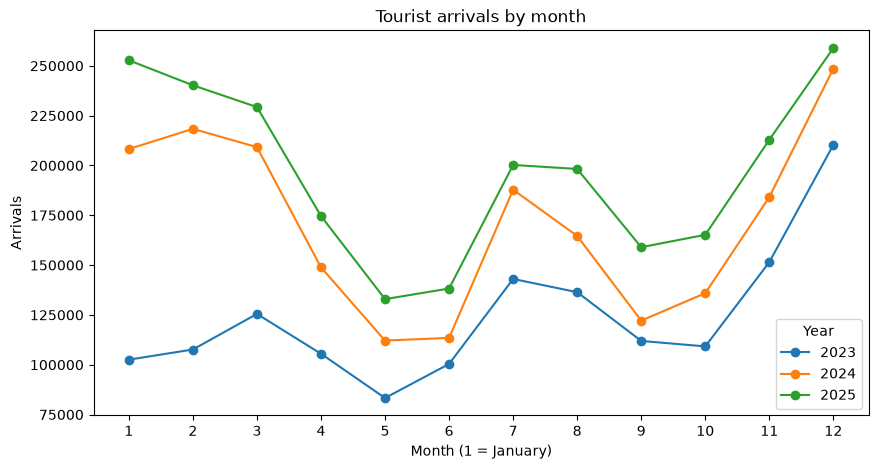

In [19]:
import matplotlib.pyplot as plt

monthly.plot(marker="o", figsize=(10, 5))
plt.title("Tourist arrivals by month")
plt.xlabel("Month (1 = January)")
plt.ylabel("Arrivals")
plt.xticks(range(1, 13))
plt.show()

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt

df_long = pd.read_csv("data/clean/tourism_long.csv")
df_long.dtypes

Country        str
Year         int64
Month          str
Arrivals     int64
Month_Num    int64
dtype: object

In [2]:
monthly = df_long.pivot_table(index="Month_Num", columns="Year",
                              values="Arrivals", aggfunc="sum")

In [3]:
print("Highest month:")
print(monthly.idxmax())
print()
print("Lowest month:")
print(monthly.idxmin())

Highest month:
Year
2023    12
2024    12
2025    12
dtype: int64

Lowest month:
Year
2023    5
2024    5
2025    5
dtype: int64


In [4]:
top10 = (df_long.groupby("Country")["Arrivals"]
         .sum()
         .sort_values(ascending=False)
         .head(10))
top10

Country
India                 1251329
Russian Federation     585998
United Kingdom         520704
Germany                386589
China                  332505
Australia              266496
France                 254067
United States          171849
Netherlands            143336
Canada                 132289
Name: Arrivals, dtype: int64

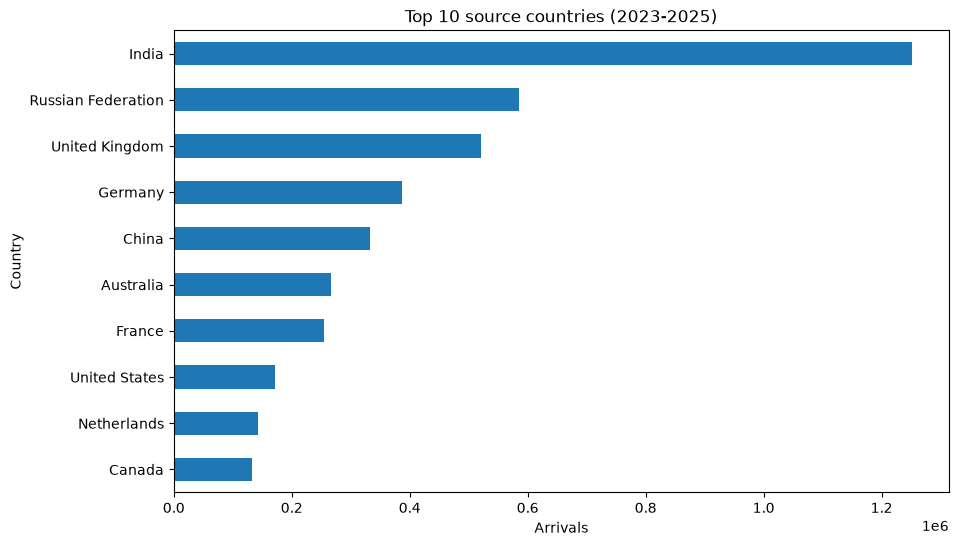

In [5]:
top10.plot(kind="barh", figsize=(10, 6))
plt.gca().invert_yaxis()
plt.title("Top 10 source countries (2023-2025)")
plt.xlabel("Arrivals")
plt.show()

In [6]:
for year in [2023, 2024, 2025]:
    print(year)
    print(df_long[df_long["Year"] == year]
          .groupby("Country")["Arrivals"]
          .sum()
          .sort_values(ascending=False)
          .head(10))
    print()

2023
Country
India                 302844
Russian Federation    197498
United Kingdom        130088
Germany               102539
China                  68789
Australia              67436
France                 56251
United States          46344
Canada                 43944
Maldives               37328
Name: Arrivals, dtype: int64

2024
Country
India                 416974
Russian Federation    201920
United Kingdom        178339
Germany               136084
China                 131681
Australia              89573
France                 88775
United States          59532
Netherlands            50116
Maldives               47222
Name: Arrivals, dtype: int64

2025
Country
India                 531511
United Kingdom        212277
Russian Federation    186580
Germany               147966
China                 132035
Australia             109487
France                109041
United States          65973
Netherlands            64164
Bangladesh             59563
Name: Arrivals, dtype: int64



In [7]:
total_all = df_long["Arrivals"].sum()

share = (top10 / total_all * 100).round(1)
print(share)
print()
print("Top 5 share:", share.head(5).sum().round(1), "%")
print("Top 10 share:", share.sum().round(1), "%")

Country
India                 21.2
Russian Federation     9.9
United Kingdom         8.8
Germany                6.5
China                  5.6
Australia              4.5
France                 4.3
United States          2.9
Netherlands            2.4
Canada                 2.2
Name: Arrivals, dtype: float64

Top 5 share: 52.0 %
Top 10 share: 68.3 %


In [8]:
by_country = df_long.pivot_table(index="Country", columns="Year",
                                 values="Arrivals", aggfunc="sum")

by_country["Change"] = by_country[2025] - by_country[2023]
by_country.sort_values("Change", ascending=False).head(10)

Year,2023,2024,2025,Change
Country,,,,
India,302844.0,416974.0,531511.0,228667.0
United Kingdom,130088.0,178339.0,212277.0,82189.0
China,68789.0,131681.0,132035.0,63246.0
France,56251.0,88775.0,109041.0,52790.0
Germany,102539.0,136084.0,147966.0,45427.0
Australia,67436.0,89573.0,109487.0,42051.0
Bangladesh,17846.0,39555.0,59563.0,41717.0
Netherlands,29056.0,50116.0,64164.0,35108.0
Poland,17946.0,44165.0,49989.0,32043.0


In [9]:
by_country["Growth_%"] = ((by_country[2025] - by_country[2023])
                          / by_country[2023] * 100).round(1)

big = by_country[by_country[2023] >= 10000]
big.sort_values("Growth_%", ascending=False).head(10)

Year,2023,2024,2025,Change,Growth_%
Country,,,,,
Bangladesh,17846.0,39555.0,59563.0,41717.0,233.8
Poland,17946.0,44165.0,49989.0,32043.0,178.6
Italy,22242.0,38709.0,50430.0,28188.0,126.7
Netherlands,29056.0,50116.0,64164.0,35108.0,120.8
Malaysia,10940.0,18259.0,23684.0,12744.0,116.5
Pakistan,10744.0,13451.0,22296.0,11552.0,107.5
Belgium,10667.0,17219.0,21056.0,10389.0,97.4
Japan,19583.0,30429.0,38153.0,18570.0,94.8
France,56251.0,88775.0,109041.0,52790.0,93.8


In [10]:
yearly_total = df_long.groupby("Year")["Arrivals"].sum()
top_countries = ["India", "Russian Federation", "United Kingdom", "Germany", "China"]

share_year = (by_country.loc[top_countries, [2023, 2024, 2025]]
              / yearly_total * 100).round(1)
share_year

Year,2023,2024,2025
Country,,,
India,20.4,20.3,22.5
Russian Federation,13.3,9.8,7.9
United Kingdom,8.7,8.7,9.0
Germany,6.9,6.6,6.3
China,4.6,6.4,5.6


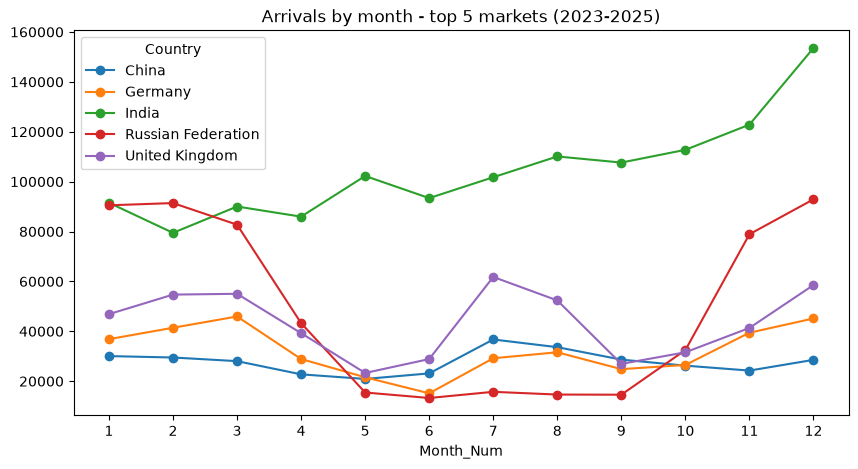

In [11]:
top5 = ["India", "Russian Federation", "United Kingdom", "Germany", "China"]

by_month = (df_long[df_long["Country"].isin(top5)]
            .pivot_table(index="Month_Num", columns="Country",
                         values="Arrivals", aggfunc="sum"))

by_month.plot(marker="o", figsize=(10, 5))
plt.title("Arrivals by month - top 5 markets (2023-2025)")
plt.xticks(range(1, 13))
plt.show()

In [12]:
by_month.idxmax()

Country
China                  7
Germany                3
India                 12
Russian Federation    12
United Kingdom         7
dtype: int64